<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/A9__regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Instructions**
1. Write the code in Python to get a simple linear regression model using 'peso' as the dependent variable and 'cintura' as the independent variable.
2. Add Python code to print the values of the slope, intercept (B0 or intercept), and partial regression coefficient (B1).
3. Write the Python code to include the line from the regression model (estimated values) along with the original (actual) data in a scatterplot.
4. Write the code in Python to calculate the residuals.
5. Separate the data between men and women and repeat the analysis.
6. At the end add a cell where you explain your conclusions.


In [38]:
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib as plt


In [ ]:
path = '/content/antropometria-dataset.csv'
df = pd.read_csv(path)
df.head()

,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,PrimaryLast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


In [ ]:

# Select the variables
data = df.loc[:, ['sexo', 'peso', 'cintura', 'cadera']]

# Remove missing values
data = data.dropna()



# Summary table by sex
summary = data.pivot_table(
    values=['peso', 'cintura', ],
    index='sexo',
    aggfunc='mean'
)

print(summary)


        cintura       peso
sexo                      
1     87.502601  67.131228
2     88.006300  62.656815


## Simple linear regression


In [ ]:

# Define variables
x = data['cintura']
y = data['peso']

# Calculate regression coefficients
B1, B0 = np.polyfit(x, y, 1)

print('Intercept (B0):', B0)
print('Slope (B1):', B1)
print('Regression coefficient (B1):', B1)

# Calculate estimated values
data['predicted_peso'] = B0 + B1 * x

# Calculate residuals
data['residuals'] = y - data['predicted_peso']

data.head()


Intercept (B0): -8.31365630882182
Slope (B1): 0.8315676239469254
Regression coefficient (B1): 0.8315676239469254


,sexo,peso,cintura,cadera,predicted_peso,residuals
0,2,73.70,98.7,106.0,73.762068,-0.062068
1,2,35.65,64.0,75.0,44.906672,-9.256672
2,2,54.80,67.6,94.3,47.900315,6.899685
3,1,33.40,60.6,72.2,42.079342,-8.679342
4,2,97.95,113.0,127.0,85.653485,12.296515


## Scatterplot


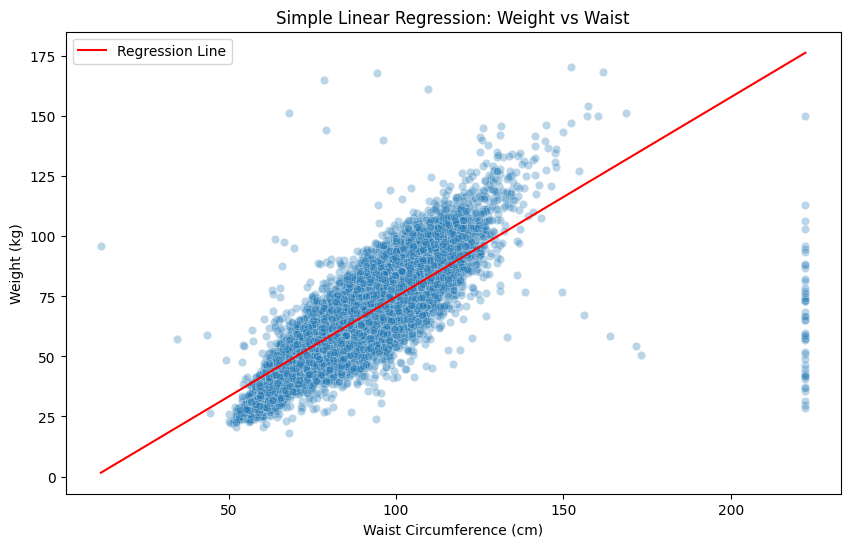

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(data=data, x='cintura', y='peso', alpha=0.3)

sns.lineplot(data=data.sort_values('cintura'),
             x='cintura', y='predicted_peso',
             color='red', label='Regression Line')

plt.title('Simple Linear Regression: Weight vs Waist')
plt.xlabel('Waist Circumference (cm)')
plt.ylabel('Weight (kg)')
plt.show()

## Separate men and women


In [ ]:

men = data.loc[data['sexo'] == 1].copy()
women = data.loc[data['sexo'] == 2].copy()

# Regression for men
B1_m, B0_m = np.polyfit(men['cintura'], men['peso'], 1)

men['predicted_peso'] = B0_m + B1_m * men['cintura']
men['residuals'] = men['peso'] - men['predicted_peso']

# Regression for women
B1_w, B0_w = np.polyfit(women['cintura'], women['peso'], 1)

women['predicted_peso'] = B0_w + B1_w * women['cintura']
women['residuals'] = women['peso'] - women['predicted_peso']

print('MEN')
print('Intercept (B0):', B0_m)
print('Slope (B1):', B1_m)

print('\nWOMEN')
print('Intercept (B0):', B0_w)
print('Slope (B1):', B1_w)


MEN
Intercept (B0): -16.501454915572427
Slope (B1): 0.9557736731097389

WOMEN
Intercept (B0): -2.18515708917072
Slope (B1): 0.7367878416907179


### Scatterplot per gender

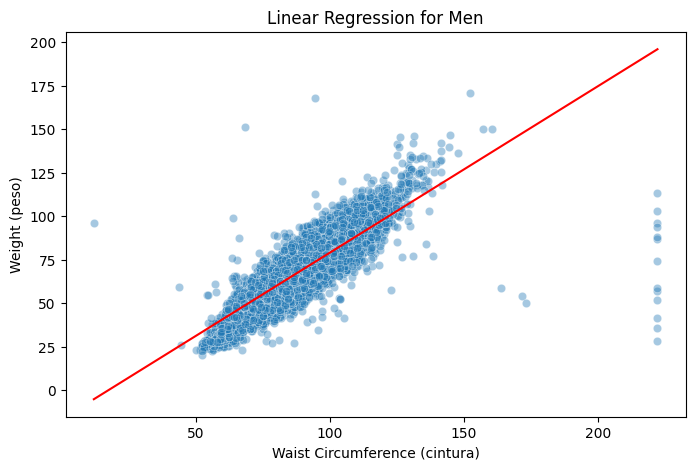

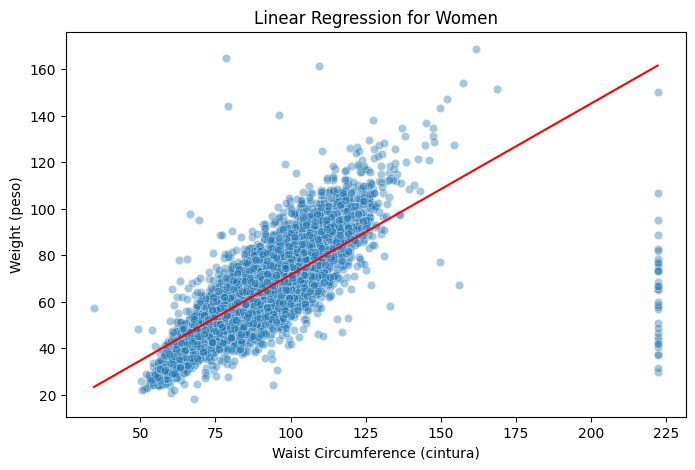

In [ ]:
# Plot for men
plt.figure(figsize=(8, 5))

sns.scatterplot(data=men, x='cintura', y='peso', alpha=0.4)
sns.lineplot(
    data=men.sort_values('cintura'),
    x='cintura',
    y='predicted_peso',
    color='red'
)

plt.title('Linear Regression for Men')
plt.xlabel('Waist Circumference (cintura)')
plt.ylabel('Weight (peso)')
plt.show()


# Plot for women
plt.figure(figsize=(8, 5))

sns.scatterplot(data=women, x='cintura', y='peso', alpha=0.4)
sns.lineplot(
    data=women.sort_values('cintura'),
    x='cintura',
    y='predicted_peso',
    color='red'
)

plt.title('Linear Regression for Women')
plt.xlabel('Waist Circumference (cintura)')
plt.ylabel('Weight (peso)')
plt.show()


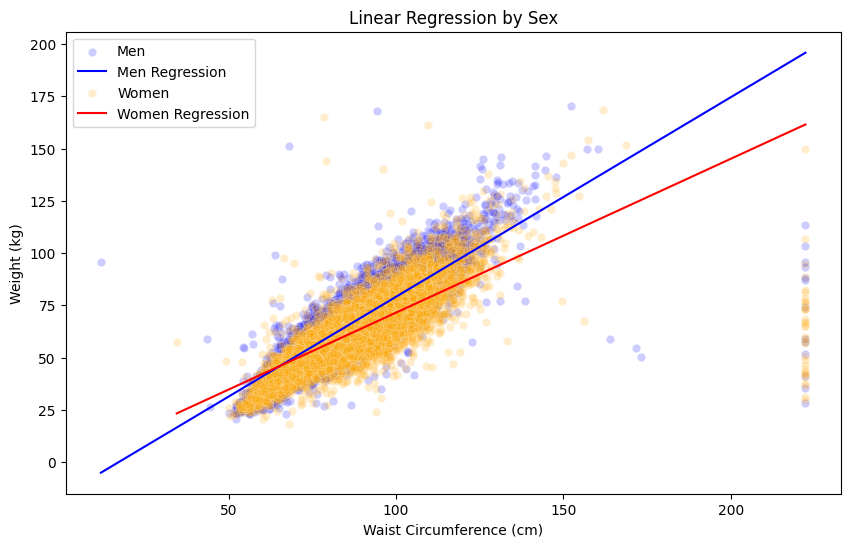

In [35]:

plt.figure(figsize=(10, 6))

# Men
sns.scatterplot(data=men, x='cintura', y='peso',
                color='blue', alpha=0.2, label='Men')

sns.lineplot(data=men.sort_values('cintura'),
             x='cintura', y='predicted_peso',
             color='blue', label='Men Regression')

# Women
sns.scatterplot(data=women, x='cintura', y='peso',
                color='orange', alpha=0.2, label='Women')

sns.lineplot(data=women.sort_values('cintura'),
             x='cintura', y='predicted_peso',
             color='red', label='Women Regression')

plt.title('Linear Regression by Sex')
plt.xlabel('Waist Circumference (cm)')
plt.ylabel('Weight (kg)')
plt.show()


## Compare regression results


In [36]:

results = pd.DataFrame({
    'Group': ['All', 'Men', 'Women'],
    'Intercept': [B0, B0_m, B0_w],
    'Slope': [B1, B1_m, B1_w]
})

print(results.iloc[:, 0:3].round(3))

# Display some actual and predicted values
print(data[['peso', 'predicted_peso', 'residuals']].head())


   Group  Intercept  Slope
0    All     -8.314  0.832
1    Men    -16.501  0.956
2  Women     -2.185  0.737
    peso  predicted_peso  residuals
0  73.70       73.762068  -0.062068
1  35.65       44.906672  -9.256672
2  54.80       47.900315   6.899685
3  33.40       42.079342  -8.679342
4  97.95       85.653485  12.296515


# Quiz questions

1. In the simple regression, cadera=  b0  + b1*peso, what would be the median value of predicted valores?



In [39]:
# Simple linear regression
x = data['peso']
y = data['cadera']

# Calculate regression coefficients
B1, B0 = np.polyfit(x, y, 1)

# Calculate predicted values
data['predicted_cadera'] = B0 + B1 * x

# Calculate median of predicted values
median_predicted = data['predicted_cadera'].median()

print('Median of predicted values:', median_predicted)

Median of predicted values: 97.18551705265611


2. What would be the correlation coefficient between 'peso' and 'cintura'?



In [40]:
correlation = data['peso'].corr(data['cintura'])

print('Correlation coefficient:', correlation)

Correlation coefficient: 0.79167686976069


3. In the simple regression, diastol = b0+ b1*sistol + b2*edad + b3*peso + b4*cintura, what would be the Durbin-Watson value?




In [41]:
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

# Create a new DataFrame
df_q3 = df.loc[:, ['diastol', 'sistol', 'edad', 'peso', 'cintura']].dropna()

# Define dependent and independent variables
X = df_q3[['sistol', 'edad', 'peso', 'cintura']]
y = df_q3['diastol']

# Add intercept (B0)
X = sm.add_constant(X)

# Multiple linear regression
model = sm.OLS(y, X).fit()

# Calculate Durbin-Watson
dw = durbin_watson(model.resid)

print('Durbin-Watson value:', round(dw, 4))

Durbin-Watson value: 1.7687


4. In the simple regression, cadera=  b0  + b1*peso, what would be the value of Intercept:?

In [42]:
# Select variables
df_q4 = df.loc[:, ['peso', 'cadera']].dropna()

# Calculate regression coefficients
B1, B0 = np.polyfit(df_q4['peso'], df_q4['cadera'], 1)

print('Intercept (B0):', B0)
print('Slope (B1):', B1)

Intercept (B0): 57.45998905926909
Slope (B1): 0.622657178579734


5. In the simple regression, cadera=  b0  + b1*peso, what would be the median value of the residuals:?

In [43]:
# Calculate regression coefficients
B1, B0 = np.polyfit(df_q4['peso'], df_q4['cadera'], 1)

# Calculate predicted values
df_q4['predicted_cadera'] = B0 + B1 * df_q4['peso']

# Calculate residuals
df_q4['residuals'] = df_q4['cadera'] - df_q4['predicted_cadera']

# Calculate median
median_residuals = df_q4['residuals'].median()

print('Median of residuals:', median_residuals)

Median of residuals: -0.649573981177717


# Conclusion

 ### Conclusions

Based on the results obtained from the simple linear regression, we can observe a strong positive relationship between waist circumference and weight, with a correlation coefficient of 0.7917.

This means that as waist circumference increases, weight also tends to increase. When analyzing men and women separately, men had a higher slope (0.956) compared to women (0.737), which shows a greater increase in estimated weight for each additional centimeter of waist circumference.

The residuals show that there are still differences between the actual and predicted values.

 I consider that waist circumference is a useful variable to estimate weight, although other factors could also be considered to improve the model's accuracy.